# Project Progress Report: Forecasting Daily High Temperature Over the Next Seven Days at Texas Weather Stations

Group HODA

## Team

* **Aidan Orines (hgn24):** data download and cleaning, the COOP date-alignment check, the shared scoring code and simple forecasts, the gradient boosting model, and this report.
* **Danylo Huk (rnj42):** the random forest model, its nearby-station features, its tuning, and the feature importance analysis.

## Project Abstract

We predict the daily high temperature (TMAX) at 280 Texas weather stations 1 to 7 days ahead, using NOAA GHCN-Daily records from 2000 to 2025. Models are trained on 2000-2019, tuned on 2020-2022, and will be tested once on 2023-2025. Every model has to beat the best simple forecast, damped anomaly, at each lead time.

We organize the inputs as a three-level hierarchy: the station's own history (micro), nearby stations (meso), and the whole state (macro). A random forest baseline and gradient boosting on these features both beat damped anomaly at leads 1 to 3, cutting the lead 1 MAE from 2.95 °C to about 2.5 °C. From lead 4 on they are level with it. Nearby stations, especially to the north, account for most of the improvement at short lead times.

## Problem Statement

**Task.** Given a station's observations through day t, predict its TMAX in °C for each of days t+1 to t+7. The forecast is issued on the morning of day t+1, once the overnight readings are in.

**Why it matters.** Daily highs drive heat safety, outdoor work, and power and water demand in Texas. We want to know how far ahead station data alone can help.

**Benchmark.** Three simple forecasts, all fitted on the training years: persistence (the coming days match today's high), climatology (the station's usual high for that date), and damped anomaly (the usual high plus a shrinking share of today's departure from it). On 2020-2022, damped anomaly is the best of the three at every lead (MAE 2.95 °C at lead 1, 3.91 °C at lead 7), so it is the forecast to beat.

**Success measure.** Lower MAE than damped anomaly at each lead, on the same station-days. We also report RMSE, and we test whether each gain is bigger than luck: stations share weather on the same days, so we rebuild the validation years 2000 times from randomly picked whole weeks and check whether the 95% range of the gain stays above 0.

**What we learned since the proposal.**

* **Dates.** COOP observers read their thermometers in the morning, so the high they file for a day usually happened the afternoon before. We move those highs back one day, after checking each station against nearby airports.
* **Gaps.** Only 280 of the 674 downloaded stations have a TMAX on at least 80% of days in both the training and validation years.
* **Where the improvement comes from.** A station's own departure from normal fades within a few days, but weather moves: what nearby stations, especially to the north, saw today is the best guide to tomorrow.
* **The limit.** Past lead 3, no model beats damped anomaly by more than luck. This answers the proposal's question of where the improvement disappears.
* **Warmer validation years.** 2020-2022 ran 0.37 °C warmer than the 2000-2019 climatology.

## Dataset

**Source.** NOAA GHCN-Daily, version 3.35-upd-2026110217: the Texas stations with TMAX records between 2000 and 2025, 674 stations and 29.5 million raw values (details in the proposal).

**Cleaned table.** One row per station and calendar day, with no days missing: 280 stations x 9,497 days = 2,659,160 station-days. The kept stations are 166 cooperative (COOP), 66 airport, and 48 RAWS stations. Each row holds that day's TMAX, TMIN, precipitation, snowfall, snow depth and wind, plus the targets `y1` to `y7`, the TMAX 1 to 7 days later.

**Cleaning** (`data_scripts/prepare_data.py`):

1. Keep only values that pass all of NOAA's quality checks, and convert them to °C and mm.
2. Move morning COOP highs back one day. `data_scripts/check_date_alignment.py` compares each COOP station's highs with nearby airports that record midnight-to-midnight days; 209 station-years at 37 stations already filed the high on the right day and are left alone.
3. Remove impossible values: temperatures outside Texas's record range (-30.6 to 48.9 °C), and both values on days where the low is above the high.
4. Keep stations with a TMAX on at least 80% of days in both the training and validation years.
5. Mark the usable rows: today's TMAX and all 7 targets present. Every method is scored on these rows only.

**Missing inputs** are left missing, since both tree models handle them: TMIN is present on 94.6% of station-days, precipitation on 80.0%, snow depth on 55.6%, and wind on 22.7%.

In [1]:
import sys
sys.path.insert(0, "../data_scripts")  # relative to this notebook's folder

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from prepare_data import load_data
from scoring import LEADS, climatology, simple_forecasts, score

RF_RESULTS = "../notebooks/random_forest_results/"
# Validated default palette: categorical slots 1 and 2, ink, grid and chart surface.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.titlelocation": "left", "axes.titlecolor": INK, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

data = load_data()
usual = climatology(data)  # each station's usual high on any date, fitted on training years only
train = data[data.usable & (data.period == "train")]
rows = data[data.usable & (data.period == "validation")]
counts = data[data.usable].period.value_counts().reindex(["train", "validation", "test"])
pd.DataFrame({"years": ["2000-2019", "2020-2022", "2023-2025"], "usable station-days": counts.map("{:,}".format)},
             index=counts.index)

,years,usable station-days
period,,
train,2000-2019,"1,825,364"
validation,2020-2022,"282,981"
test,2023-2025,"270,013"


### Distributions, correlations and outliers

The models predict each day's departure from the station's usual high (its anomaly) and add the usual high back, so the anomaly is the quantity to understand.

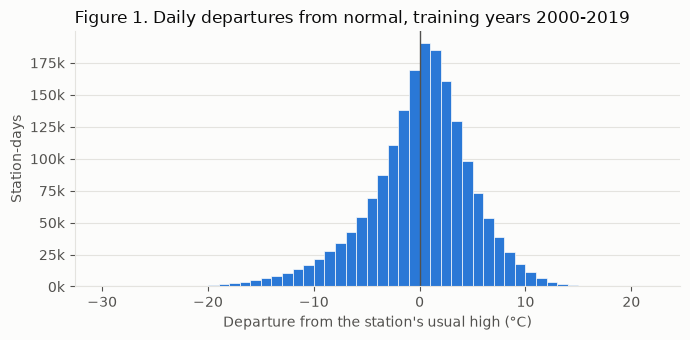

Standard deviation 4.95 °C, skew -0.63. 4.0% of days are more than 10 °C below normal, 1.4% more than 10 °C above.


In [2]:
anomaly = train.TMAX.to_numpy(float) - usual(train.STATION, train.DATE)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(anomaly, bins=np.arange(-30, 23), color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.axvline(0, color=INK2, linewidth=1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set(xlabel="Departure from the station's usual high (°C)", ylabel="Station-days",
       title="Figure 1. Daily departures from normal, training years 2000-2019")
fig.tight_layout()
plt.show()
print(f"Standard deviation {anomaly.std():.2f} °C, skew {pd.Series(anomaly).skew():.2f}. "
      f"{100 * (anomaly < -10).mean():.1f}% of days are more than 10 °C below normal, "
      f"{100 * (anomaly > 10).mean():.1f}% more than 10 °C above.")

**Distribution.** Departures have a standard deviation of about 5 °C and a long cold tail (skew -0.63): days 10 °C or more below normal are almost three times as common as days 10 °C or more above. These are cold fronts, which a forecast has to see coming.

**Outliers.** The largest departures reach about -30 °C. We keep them, since they passed NOAA's checks and our range checks.

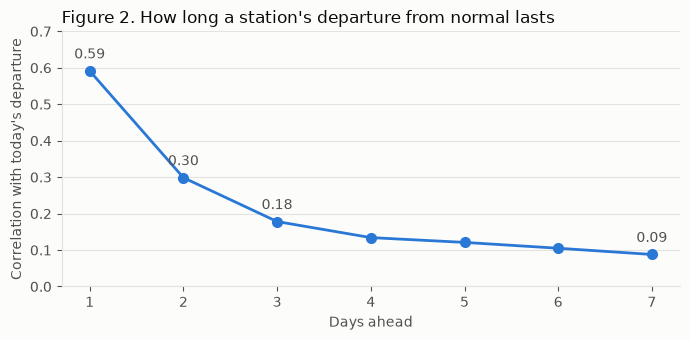

In [3]:
correlation = []
for h in LEADS:
    later = train[f"y{h}"].to_numpy(float) - usual(train.STATION, train.DATE + pd.Timedelta(days=h))
    correlation.append(np.corrcoef(anomaly, later)[0, 1])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(list(LEADS), correlation, color=BLUE, linewidth=2, marker="o", markersize=7)
for h in (1, 2, 3, 7):
    ax.annotate(f"{correlation[h - 1]:.2f}", (h, correlation[h - 1]), textcoords="offset points",
                xytext=(0, 9), ha="center", color=INK2)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set(xlabel="Days ahead", ylabel="Correlation with today's departure", xticks=list(LEADS), ylim=(0, 0.7),
       title="Figure 2. How long a station's departure from normal lasts")
fig.tight_layout()
plt.show()

**Correlation over time.** A station's departure today has a correlation of 0.59 with tomorrow's, but only 0.30 two days out and 0.18 three days out. A station's own history runs out of information within a few days, so any gain past lead 1 or 2 has to come from somewhere else.

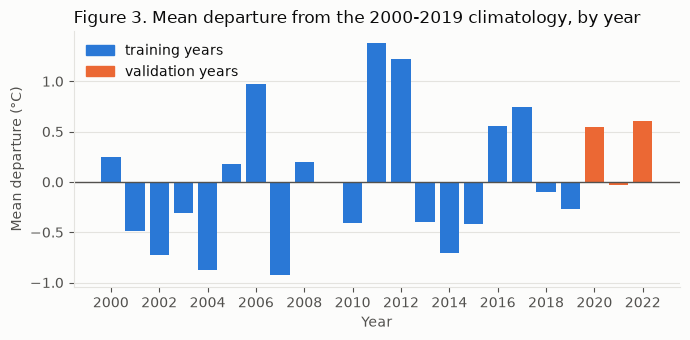

Validation years: +0.37 °C on average


In [4]:
seen = data[data.TMAX.notna() & data.period.isin(["train", "validation"])]
by_year = (pd.Series(seen.TMAX.to_numpy(float) - usual(seen.STATION, seen.DATE))
           .groupby(seen.DATE.dt.year.to_numpy()).mean())
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_year.index, by_year, width=0.8, color=[ORANGE if year >= 2020 else BLUE for year in by_year.index])
ax.axhline(0, color=INK2, linewidth=1)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set(xlabel="Year", ylabel="Mean departure (°C)", xticks=range(2000, 2023, 2),
       title="Figure 3. Mean departure from the 2000-2019 climatology, by year")
ax.legend(handles=[Patch(color=BLUE, label="training years"), Patch(color=ORANGE, label="validation years")],
          frameon=False, loc="upper left")
fig.tight_layout()
plt.show()
print(f"Validation years: {by_year.loc[2020:].mean():+.2f} °C on average")

**Year-to-year swings.** The climatology averages to zero over its own training years by construction, and 2020-2022 ran 0.37 °C warmer. That is within the usual swings (2011 ran 1.4 °C warm), but any forecast built on the climatology starts the validation years with a small cold bias.

### Insights that inform next steps

* Improving short-range forecasts needs information about weather on its way, which points to nearby stations as features (Figure 2).
* Little signal is left past 3 days, so we expect gains to fade by lead 4 and focus on leads 1 to 3.
* The cold tail means the biggest misses come from cold fronts, and RMSE, which weighs big misses more, will show them.
* Swings of up to about 1 °C between years mean a slow-moving input, like the 30-day mean TMAX in our features, can correct part of the climatology's bias.

## Methodology

### Baseline method implementation

**Simple forecasts.** Described in the Problem Statement; they set the bar.

**Random forest (Danylo).** One `RandomForestRegressor` per lead time. Each forest predicts the departure from the usual high on the target day, and the usual high is added back. It uses 31 features built from data through day t (listed under Improvements) and trains on the 1.8 million usable training rows.

**Tuning.** A staged search, with every setting trained on the same 300,000 training rows and scored on all validation rows at leads 1 and 7: depth x leaf size, then features per split, then number of trees, then the target (departure from normal vs raw TMAX). The winner is 100 trees, depth 20, at least 50 rows per leaf, 20% of features per split, predicting the departure. All 15 settings landed within 0.03 °C of each other. The final forests grow each tree on a 500,000-row bootstrap sample.

In [5]:
rf = pd.read_csv(RF_RESULTS + "validation_results.csv", index_col="lead time")
rf[["RF MAE", "Damped anomaly MAE", "MAE gain", "RF RMSE", "Damped anomaly RMSE"]]

,RF MAE,Damped anomaly MAE,MAE gain,RF RMSE,Damped anomaly RMSE
lead time,,,,,
1,2.52,2.95,0.43,3.56,4.09
2,3.42,3.64,0.22,4.69,4.90
3,3.72,3.81,0.09,5.05,5.11
4,3.82,3.86,0.04,5.16,5.17
5,3.88,3.89,0.01,5.26,5.21
6,3.88,3.90,0.03,5.26,5.23
7,3.88,3.91,0.03,5.28,5.24


In [6]:
tuning = pd.read_csv(RF_RESULTS + "tuning_table.csv", keep_default_na=False)  # keeps "None" depth and blank winner
tuning[["stage", "n_estimators", "max_depth", "min_samples_leaf", "max_features", "target",
        "MAE lead 1", "MAE lead 7", "mean MAE", "winner"]]

,stage,n_estimators,max_depth,min_samples_leaf,max_features,target,MAE lead 1,MAE lead 7,mean MAE,winner
0,1 depth x leaf,100,10,5,0.33,anomaly,2.555,3.877,3.216,
1,1 depth x leaf,100,10,20,0.33,anomaly,2.550,3.872,3.211,
2,1 depth x leaf,100,10,50,0.33,anomaly,2.551,3.872,3.211,
3,1 depth x leaf,100,20,5,0.33,anomaly,2.513,3.909,3.211,
4,1 depth x leaf,100,20,20,0.33,anomaly,2.507,3.899,3.203,
5,1 depth x leaf,100,20,50,0.33,anomaly,2.515,3.886,3.200,
6,1 depth x leaf,100,None,5,0.33,anomaly,2.517,3.921,3.219,
7,1 depth x leaf,100,None,20,0.33,anomaly,2.510,3.900,3.205,
8,1 depth x leaf,100,None,50,0.33,anomaly,2.514,3.892,3.203,
9,2 max_features,100,20,50,0.20,anomaly,2.531,3.867,3.199,<- best


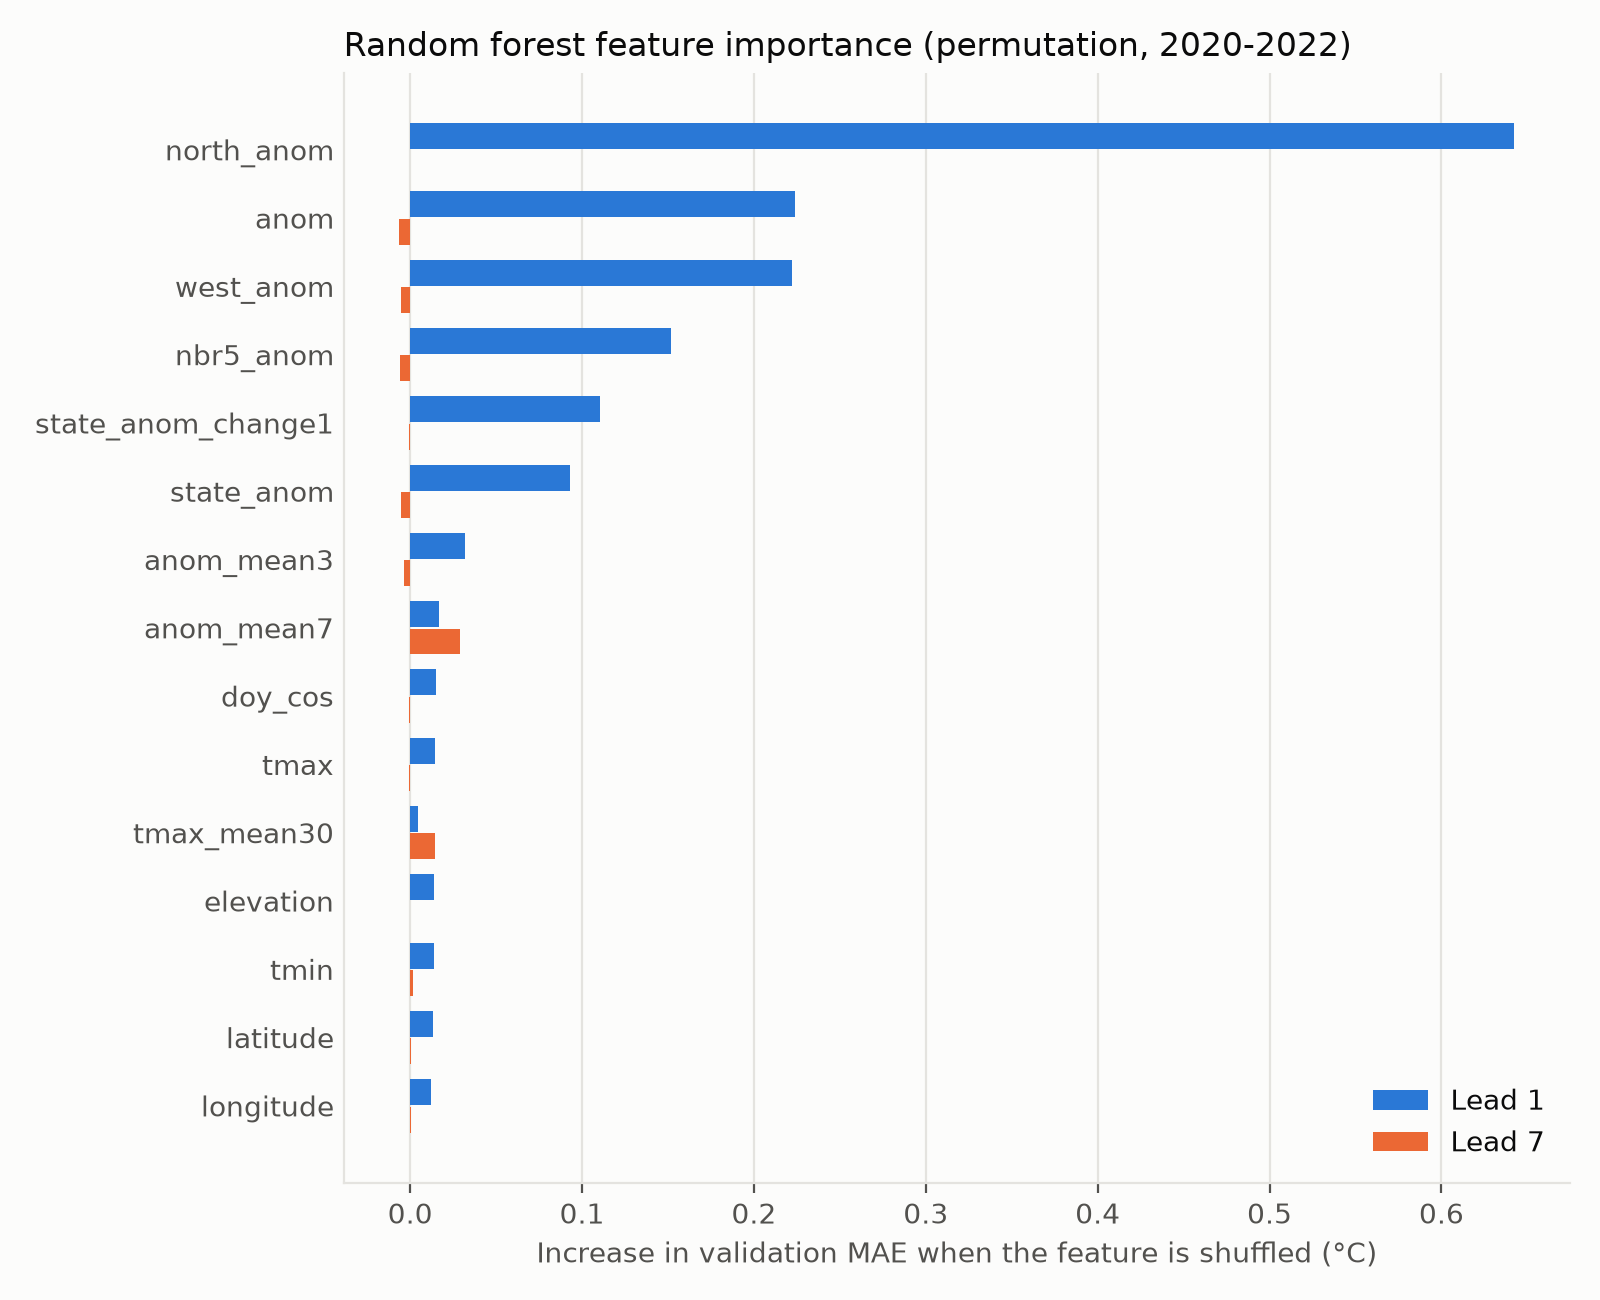

In [7]:
# Figure 4: Danylo's permutation importance, how much validation MAE rises when one feature is shuffled.
Image(RF_RESULTS + "feature_importance.png", width=620)

**Results.** The random forest beats damped anomaly at leads 1 to 3, by 0.43, 0.22 and 0.09 °C MAE, and the luck test keeps all three gains above 0. At leads 4 to 7 the gains are 0.01 to 0.04 °C and within luck, and RMSE is slightly worse than damped anomaly at leads 5 to 7.

**What the baseline reveals.** At lead 1 the most useful input is the mean anomaly at stations to the north, followed by the station's own anomaly and stations to the west (Figure 4): cold fronts reach Texas from the north and west. At lead 7 almost nothing helps, and the forest falls back to climatology. The short-range improvement comes from weather upstream, and station data runs out after about 3 days.

### Improvements and other methods implementation

**Feature engineering: a micro, meso and macro hierarchy.** We group the inputs by scale, following the micro, meso and macro tiers:

| Tier | Features |
|---|---|
| Micro: the station | TMAX today and 1-6 days back, its change since yesterday, its 7- and 30-day means; TMIN today and yesterday; the usual high today and on the target day; today's anomaly and its 3- and 7-day means; precipitation today and over 7 days; snow depth; wind; latitude, longitude, elevation |
| Meso: nearby stations | today's mean anomaly at the 5 nearest stations, at stations to the west, and at stations to the north, each within 500 km |
| Macro: the state | today's mean anomaly across all 280 stations, and its change since yesterday |

The random forest also uses the day of year. Moving from station-only features (an earlier version of gradient boosting with the station's anomaly, TMIN and precipitation over the past week) to the full hierarchy cut gradient boosting's lead 1 MAE from 2.89 to 2.54 °C. Figure 4 credits most of that to the nearby stations.

**Feature selection.** Permutation importance (Figure 4) shows which features the accuracy depends on. We also removed one feature from gradient boosting: the day of year. With it, lead 4 training RMSE falls from 4.10 to 3.83 °C while validation RMSE rises from 5.17 to 5.29 °C. All 280 stations share each date's weather, so the day of year plus the statewide anomaly pins down a single training date, and the trees memorize what followed it. The season is already in the climatology the targets are measured from.

**High-dimensionality mitigation.** Not done yet. With 29 to 31 features and 1.8 million rows the data are not high-dimensional in the usual sense, but many features overlap: the 7 daily TMAX values, the rolling means and the 4 nearby-station averages are strongly correlated. Next we will try PCA on these correlated blocks and tier-by-tier feature selection, and compare each with the full set.

**A better-fit model: gradient boosting (Aidan).** One `HistGradientBoostingRegressor` per lead time, with the same target and the same features minus the day of year. Why it should fit better: it builds trees one after another, each correcting the errors the previous ones left, which is usually the strongest approach on tabular data; it bins features, so it trains on all 1.8 million rows in about 16 s per lead (the forest takes 35-45 s per lead on 500,000-row samples); and it handles missing values natively, which matters with wind missing on 77% of station-days.

In [8]:
simple = {name: score(rows, f) for name, f in simple_forecasts(data, rows).items()}
# Gradient boosting scores from notebooks/gradient_boosting.ipynb, on the same validation rows.
gb = pd.DataFrame({"MAE": [2.54, 3.43, 3.72, 3.82, 3.89, 3.90, 3.88],
                   "RMSE": [3.59, 4.70, 5.06, 5.17, 5.28, 5.28, 5.27]}, index=rf.index)
models = {"random forest": rf.rename(columns={"RF MAE": "MAE", "RF RMSE": "RMSE"}), "gradient boosting": gb}
mae = pd.DataFrame({name: s.MAE for name, s in simple.items()} | {name: m.MAE for name, m in models.items()})
rmse = pd.DataFrame({name: s.RMSE for name, s in simple.items()} | {name: m.RMSE for name, m in models.items()})
mae.columns.name, rmse.columns.name = "MAE (°C)", "RMSE (°C)"
display(mae.round(2), rmse.round(2))

MAE (°C),persistence,climatology,damped anomaly,random forest,gradient boosting
lead time,,,,,
1,3.10,3.92,2.95,2.52,2.54
2,4.23,3.92,3.64,3.42,3.43
3,4.69,3.92,3.81,3.72,3.72
4,4.91,3.92,3.86,3.82,3.82
5,5.01,3.93,3.89,3.88,3.89
6,5.12,3.93,3.90,3.88,3.90
7,5.15,3.93,3.91,3.88,3.88


RMSE (°C),persistence,climatology,damped anomaly,random forest,gradient boosting
lead time,,,,,
1,4.53,5.25,4.09,3.56,3.59
2,5.92,5.25,4.90,4.69,4.70
3,6.49,5.25,5.11,5.05,5.06
4,6.77,5.25,5.17,5.16,5.17
5,6.94,5.25,5.21,5.26,5.28
6,7.09,5.26,5.23,5.26,5.28
7,7.12,5.26,5.24,5.28,5.27


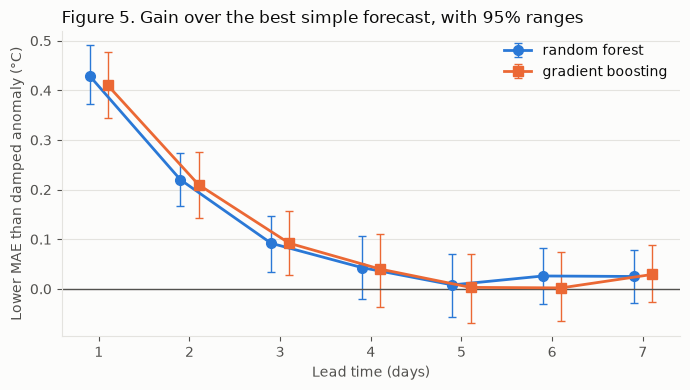

In [9]:
# MAE gain over damped anomaly and its 95% range from the week-block luck test: gradient boosting's from
# gradient_boosting.ipynb, the random forest's from the same test run on its validation predictions.
luck = {"random forest": ([0.429, 0.220, 0.092, 0.043, 0.008, 0.026, 0.025],
                          [0.373, 0.166, 0.035, -0.021, -0.057, -0.030, -0.029],
                          [0.491, 0.273, 0.147, 0.107, 0.071, 0.083, 0.079]),
        "gradient boosting": ([0.410, 0.210, 0.092, 0.040, 0.003, 0.002, 0.029],
                              [0.345, 0.143, 0.027, -0.036, -0.068, -0.064, -0.027],
                              [0.477, 0.276, 0.157, 0.110, 0.071, 0.074, 0.088])}
leads = np.array(LEADS)
fig, ax = plt.subplots(figsize=(7, 4))
for (name, ranges), color, marker, shift in zip(luck.items(), (BLUE, ORANGE), ("o", "s"), (-0.1, 0.1)):
    gain, low, high = map(np.array, ranges)
    ax.errorbar(leads + shift, gain, yerr=[gain - low, high - gain], color=color, marker=marker, markersize=7,
                linewidth=2, elinewidth=1, capsize=3, label=name)
ax.axhline(0, color=INK2, linewidth=1)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set(xticks=leads, xlabel="Lead time (days)", ylabel="Lower MAE than damped anomaly (°C)",
       title="Figure 5. Gain over the best simple forecast, with 95% ranges")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

**Results.** On the same features, gradient boosting is within 0.03 °C of the random forest at every lead. Both beat damped anomaly at leads 1 to 3, with 95% ranges above 0, and both are level with it from lead 4 on (Figure 5). So far the features matter much more than the algorithm.

**Tuning.** The random forest is tuned (above). Gradient boosting still uses its defaults (300 iterations, learning rate 0.1), so tuning it is the main way it could pull ahead.

**Plan for the remaining week (to Nov 27).**

1. Tune gradient boosting on the validation years: learning rate, leaf size and L2 penalty. (Aidan)
2. Tier comparison: train each model on micro only, micro + meso, and all three tiers. This measures what each tier adds and gives a station-only baseline. (Aidan for gradient boosting, Danylo for the random forest)
3. Try PCA and feature selection on the correlated feature blocks. (Aidan for gradient boosting, Danylo for the random forest)
4. Fix the final settings, then score each model once on the 2023-2025 test years. (Both)

## Teaming Strategy

| Name | Contribution | Section(s) Authored / Tasks Completed |
|---|---|---|
| Aidan Orines | Downloaded and cleaned the GHCN-Daily data, checked the COOP date alignment against airports, and wrote the shared scoring code and simple forecasts. Built the gradient boosting model on the shared features, the week-block luck test and the day-of-year check. | Problem Statement, Dataset, gradient boosting, feature selection, this report; `data_scripts/`, `simple_forecasts.ipynb`, `gradient_boosting.ipynb` |
| Danylo Huk | Built and tuned the random forest: one forest per lead time on station history plus nearby-station features, with a staged search over depth, leaf size, features per split and number of trees. It beats damped anomaly at leads 1 to 3 (by 0.43 °C MAE at lead 1) and is level with it from lead 4. Produced the feature importance analysis, which shows that nearby stations, especially to the north, drive the improvement at short lead times. | Baseline method, nearby-station features, feature importance; `random_forest.ipynb` |

## Mitigation Plan

| Date | Milestone | Owner |
|---|---|---|
| Fri Nov 20 | Progress report submitted | Both |
| Fri Nov 27 | Gradient boosting tuned; tier comparison; PCA and feature selection compared | Aidan for gradient boosting, Danylo for the random forest |
| Tue Dec 1, 1:30 PM | Test-year results, slides and recorded presentation | Both |
| Fri Dec 4 | Final report and code | Both |

**Checkpoints.** We meet every Friday and track the work on GitHub, one branch per model, merged into `main` when it works.

**What if we fail.**

* **Gradient boosting doesn't beat the random forest after tuning:** we keep the random forest as the final model and report that the features matter more than the algorithm.
* **No gains past lead 3:** this is already our finding. We focus on leads 1 to 3 and report leads 4 to 7 as the limit of station data.
* **Test results come in worse than validation:** we report them as they are. Settings are chosen on validation only, and the test years are scored once.
* **A teammate is unavailable:** the other takes over the critical work and cuts the scope to one model.